# LAB 09 — Named Entity Recognition and Information Extraction

Notebook trình bày từng mục riêng theo W9.pdf. Chạy từ thư mục `lab9`; dữ liệu trong `data/`, các bảng CSV trong `result/`.

## 12. Prediction Before Experiment

Trước khi chạy, dự đoán: (1) pretrained Transformer có thể cải thiện NER nhờ context hai chiều; (2) entity dài khó hơn vì phải dự đoán đúng cả span; (3) entity hiếm dễ bị bỏ sót hoặc gán sai loại vì ít ví dụ. Đối chiếu các giả thuyết sau khi xem kết quả.

## 13. Baseline

Baseline dùng Logistic Regression gán BIO cho từng từ. Features gồm token hiện tại, prefix/suffix, chữ hoa/chữ số, word shape, POS và cửa sổ lân cận. DictVectorizer biến chúng thành vector thưa; mô hình này không có pretrained contextual representation.

## 14. Transformer Token Classification

BERT tạo contextual representation cho từng vị trí. Classification head tuyến tính áp dụng cho mọi token: `Z = HW + b`, với `Z ∈ R^(T×C)` và `C=9` BIO labels. Special tokens và subword phụ dùng `-100`, nên không đóng góp vào loss.

## 15. Calculation Exercise 3 — Shape

Theo giả định đề bài: `B=8`, `T=128`, `d=768`, `C=9`. Hidden states `H`: `(8,128,768)`; weight `W`: `(768,9)`; logits `Z=HW+b`: `(8,128,9)`; labels `Y`: `(8,128)`.

*Lưu ý:* `d=768` là giả định của bài tính; thực nghiệm dùng BERT-Tiny có hidden size 128.

## 16. Core Implementation — Chạy lại thực nghiệm

Cell dưới chạy toàn bộ baseline, fine-tuning, đánh giá và sinh CSV/biểu đồ nếu thiếu kết quả. Đặt `RUN_EXPERIMENTS=True` để chạy lại; mặc định dùng kết quả đã có để không fine-tune lại mỗi lần mở notebook.

In [1]:
from pathlib import Path
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS or not Path("result/results.csv").exists():
    from baseline_ner import run_all
    run_all()
else:
    print("Đã có kết quả. Đặt RUN_EXPERIMENTS=True để chạy lại toàn bộ thí nghiệm.")

Đã có kết quả. Đặt RUN_EXPERIMENTS=True để chạy lại toàn bộ thí nghiệm.


## 18. Experiment 2 — Baseline vs Transformer

So sánh hai model trên cùng test split bằng exact entity precision, recall và F1.

In [2]:
from IPython.display import display
import pandas as pd
results = pd.read_csv("result/results.csv")
display(results)

,model,precision,recall,entity_f1,entity_support,token_accuracy,training_seconds,parameters
0,Logistic Regression token features,0.656896,0.793555,0.718788,5648,0.946441,86.049233,1000791
1,BERT-Tiny fine-tuned,0.471827,0.551523,0.508571,5648,0.916744,137.310027,4370569


### Thảo luận Experiment 2

Logistic Regression đạt entity F1 **0.719**, cao hơn BERT-Tiny **0.509**; precision/recall lần lượt là **0.657/0.794** và **0.472/0.552**. Vì vậy dự đoán ban đầu Transformer sẽ tốt hơn không được xác nhận trong cấu hình này. Đây không phải kết luận rằng baseline luôn tốt hơn. Token accuracy cao hơn entity F1 vì metric token không đòi hỏi khớp nguyên span.

## 19. Experiment 3 — Entity-Level Evaluation

Entity được biểu diễn bằng câu, vị trí bắt đầu, kết thúc và loại. Chỉ tính đúng nếu toàn bộ boundary và type trùng gold.

In [3]:
entity_metrics = pd.read_csv("result/entity_metrics.csv")
display(entity_metrics)

,model,entity_type,precision,recall,f1,support
0,Logistic Regression token features,Overall,0.656896,0.793555,0.718788,5648
1,Logistic Regression token features,PER,0.721721,0.840445,0.776571,1617
2,Logistic Regression token features,ORG,0.537003,0.698977,0.607376,1661
3,Logistic Regression token features,LOC,0.770923,0.861511,0.813703,1668
4,Logistic Regression token features,MISC,0.574398,0.747863,0.649752,702
5,BERT-Tiny fine-tuned,Overall,0.471827,0.551523,0.508571,5648
6,BERT-Tiny fine-tuned,PER,0.401982,0.576994,0.473845,1617
7,BERT-Tiny fine-tuned,ORG,0.412709,0.387116,0.399503,1661
8,BERT-Tiny fine-tuned,LOC,0.605967,0.706235,0.652270,1668
9,BERT-Tiny fine-tuned,MISC,0.463415,0.514245,0.487508,702


## 20. Precision, Recall, F1

Precision = TP/(TP+FP): tỷ lệ entity dự đoán đúng trong các entity model đã dự đoán. Recall = TP/(TP+FN): tỷ lệ entity gold được tìm ra. F1 = 2×Precision×Recall/(Precision+Recall), cân bằng precision và recall. Token accuracy có thể cao do nhãn O phổ biến nên không thay thế exact entity F1.

## 21. Experiment 4 — Entity Type Analysis

Báo cáo riêng PER, ORG, LOC, MISC và Overall; support là số span gold của mỗi loại.

In [4]:
by_type = entity_metrics[entity_metrics.entity_type != "Overall"].copy()
display(by_type)

,model,entity_type,precision,recall,f1,support
1,Logistic Regression token features,PER,0.721721,0.840445,0.776571,1617
2,Logistic Regression token features,ORG,0.537003,0.698977,0.607376,1661
3,Logistic Regression token features,LOC,0.770923,0.861511,0.813703,1668
4,Logistic Regression token features,MISC,0.574398,0.747863,0.649752,702
6,BERT-Tiny fine-tuned,PER,0.401982,0.576994,0.473845,1617
7,BERT-Tiny fine-tuned,ORG,0.412709,0.387116,0.399503,1661
8,BERT-Tiny fine-tuned,LOC,0.605967,0.706235,0.652270,1668
9,BERT-Tiny fine-tuned,MISC,0.463415,0.514245,0.487508,702


### Thảo luận Experiment 4

LOC có F1 cao nhất ở cả hai model: baseline **0.814**, BERT-Tiny **0.652**. ORG thấp nhất: **0.607** và **0.400**. Support MISC thấp hơn các nhóm khác nên cần thận trọng khi so sánh.

## 22. Experiment 5 — Entity Length

Chia entity theo độ dài 1, 2, 3 và 4+ từ; tính exact span precision/recall/F1 theo từng nhóm.

,model,entity_length,precision,recall,f1,gold_support,predicted_support
0,Logistic Regression token features,1,0.606838,0.814494,0.695496,3574,4797
1,Logistic Regression token features,2,0.798196,0.797297,0.797746,1776,1774
2,Logistic Regression token features,3,0.663265,0.550847,0.601852,236,196
3,Logistic Regression token features,4+,0.446429,0.403226,0.423729,62,56
4,BERT-Tiny fine-tuned,1,0.428378,0.709569,0.534232,3574,5920
5,BERT-Tiny fine-tuned,2,0.854325,0.317005,0.462423,1776,659
6,BERT-Tiny fine-tuned,3,0.695652,0.067797,0.123552,236,23
7,BERT-Tiny fine-tuned,4+,0.000000,0.000000,0.000000,62,0


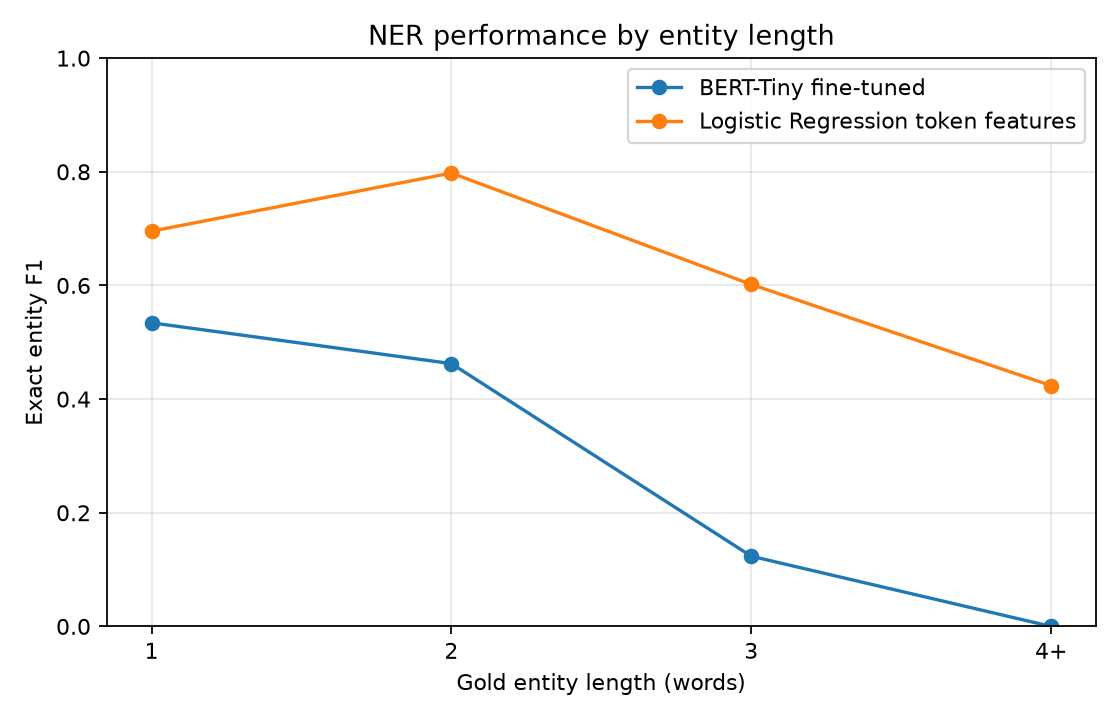

In [5]:
length_table = pd.read_csv("result/entity_length_analysis.csv")
display(length_table)
from IPython.display import Image, display as show
show(Image(filename="entity_length_analysis.png"))

### Thảo luận Experiment 5

BERT-Tiny F1 là **0.534** ở entity 1 từ, **0.462** ở 2 từ, **0.124** ở 3 từ và **0.000** ở 4+ từ. Bucket cuối có 62 gold spans và không có dự đoán đúng. Baseline đạt F1 cao nhất ở bucket 2 từ (**0.798**). Kích thước mẫu và kiểu entity cũng ảnh hưởng.

## 23. Experiment 6 — Error Analysis

Bảng có tối thiểu 5 false positives, 5 false negatives và 5 boundary errors lấy từ test.

In [6]:
errors = pd.read_csv("result/error_examples.csv")
display(errors)

,sentence_id,text,gold_entity,predicted_entity,gold_type,predicted_type,error_type,explanation
0,0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",JAPAN; CHINA,CHINA,LOC;PER,LOC,False positive / spurious entity,Model dự đoán entity không khớp span và type g...
1,1,Nadim Ladki,Nadim Ladki,Nadim,PER,PER,False positive / spurious entity,Model dự đoán entity không khớp span và type g...
2,1,Nadim Ladki,Nadim Ladki,Ladki,PER,PER,False positive / spurious entity,Model dự đoán entity không khớp span và type g...
3,2,"AL-AIN , United Arab Emirates 1996-12-06",AL-AIN; United Arab Emirates,AL-AIN,LOC;LOC,PER,False positive / spurious entity,Model dự đoán entity không khớp span và type g...
4,2,"AL-AIN , United Arab Emirates 1996-12-06",AL-AIN; United Arab Emirates,United,LOC;LOC,LOC,False positive / spurious entity,Model dự đoán entity không khớp span và type g...
5,0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",CHINA,JAPAN; CHINA,PER,LOC;LOC,False negative / missing or wrong entity,Entity gold bị bỏ sót hoặc dự đoán sai span/ty...
6,1,Nadim Ladki,Nadim Ladki,Nadim; Ladki,PER,PER;PER,False negative / missing or wrong entity,Entity gold bị bỏ sót hoặc dự đoán sai span/ty...
7,2,"AL-AIN , United Arab Emirates 1996-12-06",AL-AIN,AL-AIN; United; Arab; Emirates,LOC,PER;LOC;LOC;LOC,False negative / missing or wrong entity,Entity gold bị bỏ sót hoặc dự đoán sai span/ty...
8,2,"AL-AIN , United Arab Emirates 1996-12-06",United Arab Emirates,AL-AIN; United; Arab; Emirates,LOC,PER;LOC;LOC;LOC,False negative / missing or wrong entity,Entity gold bị bỏ sót hoặc dự đoán sai span/ty...
9,3,Japan began the defence of their Asian Cup tit...,Asian Cup,Japan; Asian; Cup; Syria,MISC,LOC;MISC;MISC;LOC,False negative / missing or wrong entity,Entity gold bị bỏ sót hoặc dự đoán sai span/ty...


### Thảo luận Experiment 6

False positive là span/type dự đoán không khớp gold; false negative là entity gold không được nhận diện chính xác; boundary error xảy ra khi vùng dự đoán chồng lấn nhưng ranh giới khác. Ví dụ tên nhiều từ bị tách thành các từ riêng. Điều đó làm exact entity F1 giảm dù một số token có thể được gán gần đúng.

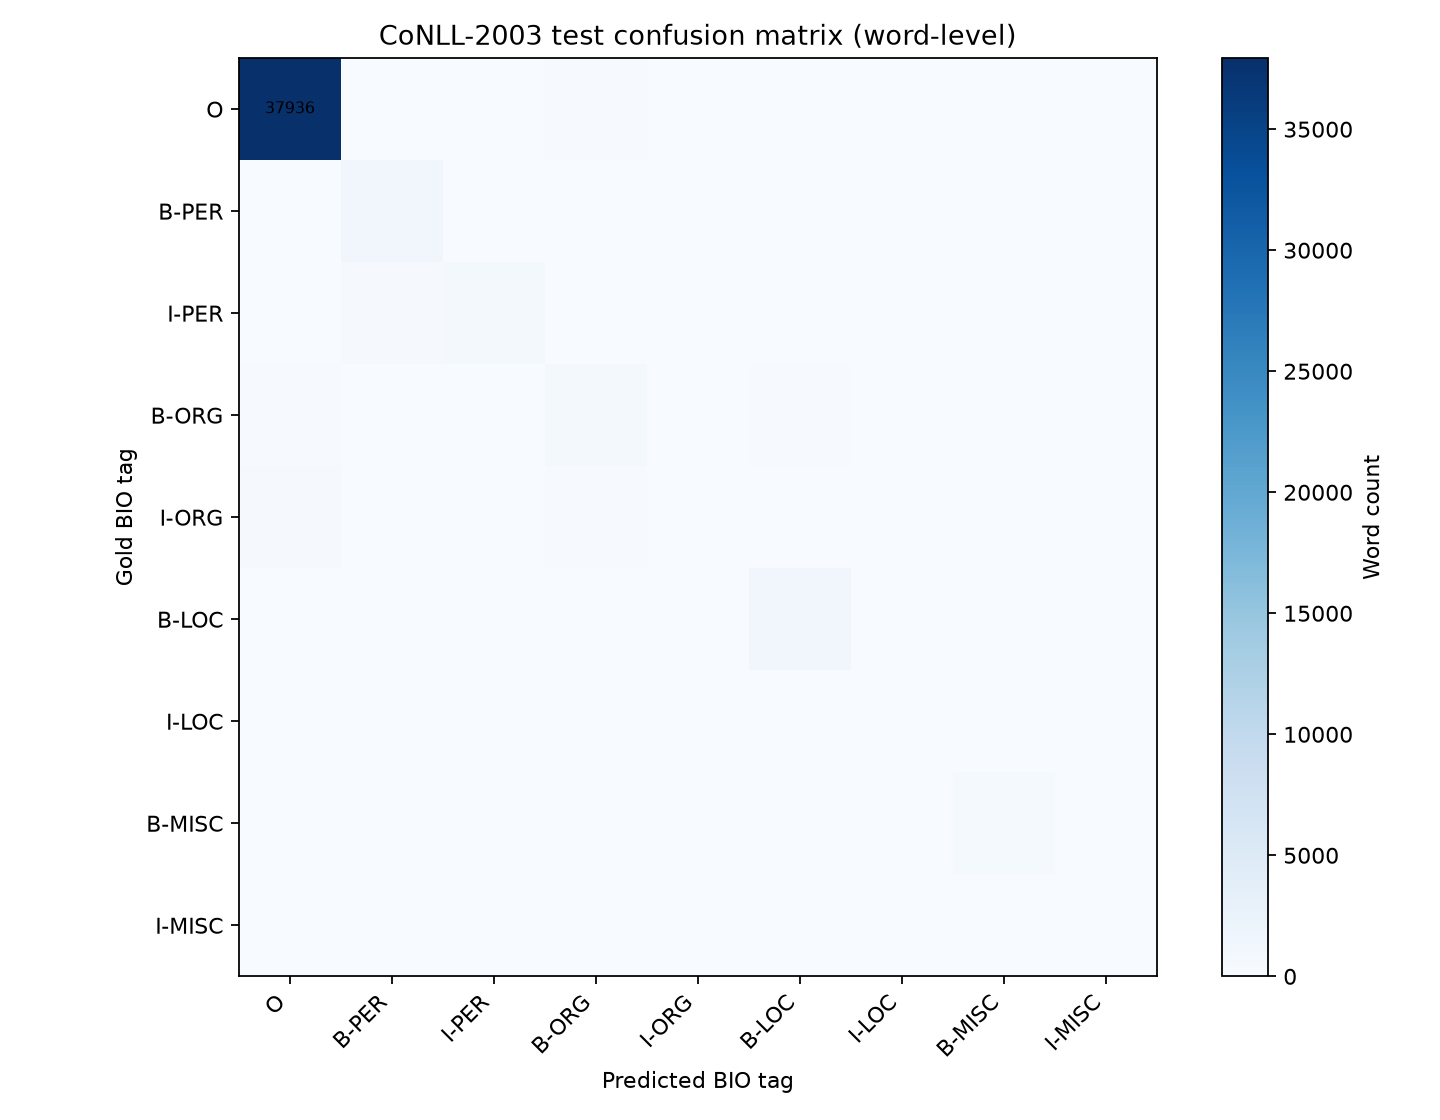

In [7]:
show(Image(filename="confusion_matrix.png"))

## 24. Context Analysis

Các ví dụ dưới đây cho thấy một surface form có thể nhận entity type khác nhau trong những context khác nhau.

In [8]:
contexts = pd.read_csv("result/context_examples.csv")
display(contexts)

,surface_form,type_a,context_a,type_b,context_b
0,japan,LOC,"SOCCER - JAPAN GET LUCKY WIN , CHINA",ORG,currencies by the Bank of Japan ( BOJ ) govern...
1,china,PER,"JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .",LOC,But China saw their luck desert them
2,united,LOC,"AL-AIN , United Arab Emirates 1996-12-06",ORG,GUNMEN WOUND TWO MANCHESTER UNITED FANS IN AUS...
3,arab,LOC,"AL-AIN , United Arab Emirates 1996-12-06",MISC,SOCCER - ARAB CONTRACTORS WIN AFRICAN CUP WINNERS
4,asian,MISC,began the defence of their Asian Cup title wit...,ORG,that the Association of Southeast Asian Nation...


## 25. Application — Information Extraction

NER tìm span và loại entity; Information Extraction ánh xạ chúng thành trường dữ liệu như PERSON, ORGANIZATION và LOCATION.

## 26. Mini Information Extraction Task

Chuyển entity trong 30 câu đầu của test thành cấu trúc JSON với các trường PERSON, ORGANIZATION, LOCATION.

In [9]:
ie_rows = pd.read_csv("result/information_extraction.csv")
display(ie_rows.head(10))

,sentence_id,text,gold_structured_json,extracted_structured_json,gold_entity_count,predicted_entity_count,exact_matches
0,0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","{""PERSON"": [""CHINA""], ""ORGANIZATION"": [], ""LOC...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",2,2,1
1,1,Nadim Ladki,"{""PERSON"": [""Nadim Ladki""], ""ORGANIZATION"": []...","{""PERSON"": [""Nadim"", ""Ladki""], ""ORGANIZATION"":...",1,2,0
2,2,"AL-AIN , United Arab Emirates 1996-12-06","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [""AL-AIN""], ""ORGANIZATION"": [], ""LO...",2,4,0
3,3,Japan began the defence of their Asian Cup tit...,"{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",2,2,2
4,4,But China saw their luck desert them in the se...,"{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",2,2,2
5,5,China controlled most of the match and saw sev...,"{""PERSON"": [""Igor Shkvyrin""], ""ORGANIZATION"": ...","{""PERSON"": [""Igor Shkvyrin""], ""ORGANIZATION"": ...",2,3,2
6,6,Oleg Shatskiku made sure of the win in injury ...,"{""PERSON"": [""Oleg Shatskiku""], ""ORGANIZATION"":...","{""PERSON"": [""Oleg"", ""Shatskiku""], ""ORGANIZATIO...",1,2,0
7,7,The former Soviet republic was playing in an A...,"{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",0,0,0
8,8,Despite winning the Asian Games title two year...,"{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",1,1,1
9,9,Two goals from defensive errors in the last si...,"{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...","{""PERSON"": [], ""ORGANIZATION"": [], ""LOCATION"":...",2,2,2


## 27. Evaluate IE on 30 sentences

Tính exact entity precision/recall/F1 trên 30 câu; span và loại phải khớp. Đây là đánh giá trích xuất entity, chưa đánh giá các bước downstream như chuẩn hóa hay liên kết thực thể.

In [10]:
ie_metrics = pd.read_csv("result/information_extraction_metrics.csv")
display(ie_metrics)

,sample_sentences,precision,recall,f1,gold_entities,predicted_entities,true_positive,false_positive,false_negative
0,30,0.448276,0.490566,0.468468,53,58,26,32,27


## 28. AI Usage Disclosure

AI hỗ trợ khung code, alignment, bảng/biểu đồ và bản nháp nhận xét dựa trên kết quả. Người học cần đọc, hiểu và tự chỉnh sửa nội dung theo yêu cầu môn học.

## 29. Deliverables

`README.md`, `calculations.md`, `prediction.md`, `baseline_ner.py`, hai notebook, các CSV trong `result/`, hai biểu đồ PNG, `error_analysis.md`, `information_extraction.py` và `reflection.md`.

## 30. Rubric — Tự rà soát

| Hạng mục | Nội dung đã có |
|---|---|
| Theory/calculation | BIO, boundary, tensor shapes |
| Prediction | Ba giả thuyết trước thí nghiệm |
| Alignment | first-subword và ignore index |
| Baseline/Transformer | hai mô hình, cùng test split |
| Evaluation | entity, type, length, errors |
| Application | trích PERSON/ORG/LOCATION, đánh giá 30 câu |
| Reflection | 300–500 từ |

## 31. Individual Learning Check

1. Sequence classification gán nhãn cho cả câu; token classification cho từng token.
2. BIO biểu diễn điểm bắt đầu và phần tiếp theo của entity.
3. B-PER bắt đầu entity Person; I-PER tiếp nối Person.
4. Tokenizer chia word thành subword nên phải căn nhãn.
5. -100 bỏ vị trí khỏi loss, không xóa khỏi input.
6. Token accuracy có thể cao do nhãn O phổ biến.
7. Exact entity F1 cần đúng type và boundary.
8. Tên nhiều từ, dấu câu, context mơ hồ dễ gây lỗi boundary.
9. Contextual representation giúp phân biệt cùng từ trong ngữ cảnh khác nhau.
10. NER tìm entity/type; IE biến kết quả thành cấu trúc.

## 32. Reflection

Qua bài lab, tôi hiểu rằng cùng một pretrained Transformer có thể được dùng cho sequence classification và token classification vì encoder vẫn tạo contextual representation cho từng token. Điểm khác nằm ở prediction head và cách xác định đầu ra. Với sequence classification, thường lấy representation của token đặc biệt đầu câu rồi đưa qua một lớp phân loại để tạo một nhãn cho toàn câu. Với token classification, áp dụng lớp phân loại lên representation tại từng vị trí, vì mỗi từ có thể mang nhãn BIO riêng. Do đó, kiến trúc encoder có thể giữ nguyên trong khi head và nhãn mục tiêu thay đổi theo tác vụ.

NER cũng cho thấy dữ liệu cần được căn chỉnh cẩn thận trước khi tính loss. Annotation của CoNLL-2003 gắn với từ, nhưng tokenizer BERT có thể chia từ thành nhiều subword. Trong bài này, subword đầu nhận nhãn của từ; subword tiếp theo, special token và padding được gán ignore index -100. Cách làm đó bảo đảm mỗi từ chỉ đóng góp một nhãn vào loss, đồng thời cho phép Transformer xử lý chuỗi subword. Khi đánh giá, dự đoán được đưa về word level rồi chuyển BIO thành span để so sánh cả ranh giới lẫn loại entity.

Kết quả làm tôi nhận ra pretrained model không tự động bảo đảm điểm số cao hơn baseline. Trên test split lần chạy này, Logistic Regression dùng token và ngữ cảnh lân cận đạt exact entity F1 khoảng 0,719, cao hơn BERT-Tiny fine-tune hai epoch với F1 khoảng 0,509. Baseline cũng có token accuracy cao hơn. Điều này phản ánh cấu hình và thời lượng huấn luyện cụ thể, chứ không chứng minh Logistic Regression luôn tốt hơn Transformer. BERT-Tiny có ít tầng và chỉ được fine-tune ngắn trên CPU; việc chọn epoch theo validation giúp hạn chế chọn trực tiếp trên test nhưng không loại hết ảnh hưởng của siêu tham số.

Phân tích theo độ dài cho thấy BERT-Tiny nhận diện entity một từ tốt hơn entity dài trong lần chạy này; F1 giảm mạnh ở các nhóm ba từ và bốn từ trở lên. Error analysis có ví dụ `Nadim Ladki` bị tách thành hai span và `United Arab Emirates` bị chia nhỏ. Các lỗi này giải thích vì sao token-level accuracy không đủ để đánh giá NER: nhiều token có thể gần đúng nhưng span hoàn chỉnh vẫn sai. Một bước tiếp theo hợp lý là huấn luyện lâu hơn, kiểm tra learning rate và dùng entity-level validation để chọn cấu hình, sau đó đánh giá lại trên test một lần. Tôi cũng sẽ phân biệt kết quả quan sát được với giả thuyết về nguyên nhân, nhất là khi mẫu entity dài nhỏ hơn nhiều so với entity một từ.

## 33. Bridge to Question Answering

NER gán BIO cho mọi token để tìm các thực thể thuộc loại đã định. Question Answering dự đoán vị trí bắt đầu/kết thúc của câu trả lời trong context dựa trên câu hỏi. Cả hai dùng contextual token representations nhưng prediction head và mục tiêu khác nhau.